# Problem 1 — RNN, LSTM and GRU on sequences

**Student ID:** 2026AK05702  
**Name :** POOJA MUDULI

**Chosen hyperparameters:** hidden size h=64; model seeds 42, 123, 2026. The instructor's revised guidance supersedes the individualisation table.  
**Training:** HAR comparison 8 epochs, adding problem 5 epochs, hidden-size sweep 8 epochs, gradient-clipping ablation 5 epochs. Adam learning rate 1e-3, batch size 128. Validation splits are subject-wise for HAR; test data are never used for checkpoint selection.

**How to execute:** Google Colab → Runtime → Change runtime type → T4 GPU → Restart session → Run all. Allow substantial time for the 36 adding runs (5 epochs each), 9 HAR runs, 8 sweep runs, 6 clipping runs and 3 gradient-profile training runs. The notebook downloads UCI HAR and creates all datasets automatically. Save the notebook with outputs and download `results.csv`, `problem1/figures/` and `problem1_analysis.txt` after execution.


In [1]:
import time
notebook_start = time.perf_counter()

In [2]:
#Import the required libraries
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import random
import time
import os
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Check GPU availability and PyTorch version

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

Device: cuda
PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [4]:
# Configure model parameters and random seeds

import random

HIDDEN_SIZE = 64
MODEL_DIM = 128
NUM_HEADS = 4
SEEDS = [42, 123, 2026]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEEDS[0])

assert MODEL_DIM % NUM_HEADS == 0

print("Hidden size:", HIDDEN_SIZE)
print("Transformer width:", MODEL_DIM)
print("Attention heads:", NUM_HEADS)
print("Random seeds:", SEEDS)

Hidden size: 64
Transformer width: 128
Attention heads: 4
Random seeds: [42, 123, 2026]


In [5]:
# Download and extract the UCI HAR dataset

import urllib.request
import zipfile
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

dataset_dir = Path("har")
dataset_dir.mkdir(exist_ok=True)

urllib.request.urlretrieve(url, "har.zip")

with zipfile.ZipFile("har.zip", "r") as zip_ref:
    zip_ref.extractall(dataset_dir)

for nested_zip in dataset_dir.rglob("UCI HAR Dataset.zip"):
    with zipfile.ZipFile(nested_zip, "r") as zip_ref:
        zip_ref.extractall(dataset_dir)

print("Dataset downloaded and extracted successfully!")
print("Extracted contents:", [p.name for p in dataset_dir.iterdir()])

Dataset downloaded and extracted successfully!
Extracted contents: ['UCI HAR Dataset', 'UCI HAR Dataset.zip', 'UCI HAR Dataset.names', '__MACOSX']


In [6]:
# Load the UCI HAR sensor data, activity labels, and subject IDs

data_path = Path("har/UCI HAR Dataset")

channels = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

def load_har_data(split):
    signals = []

    for channel in channels:
        file_path = data_path / split / "Inertial Signals" / f"{channel}_{split}.txt"
        signal = np.loadtxt(file_path, dtype=np.float32)
        signals.append(signal)

    X = np.stack(signals, axis=2)

    y = np.loadtxt(
        data_path / split / f"y_{split}.txt",
        dtype=np.int64
    ) - 1

    subjects = np.loadtxt(
        data_path / split / f"subject_{split}.txt",
        dtype=np.int64
    )

    return X, y, subjects

X_train, y_train, subjects_train = load_har_data("train")
X_test, y_test, subjects_test = load_har_data("test")

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)
print("Training subjects:", len(np.unique(subjects_train)))
print("Testing subjects:", len(np.unique(subjects_test)))

Training data shape: (7352, 128, 9)
Testing data shape: (2947, 128, 9)
Training labels shape: (7352,)
Testing labels shape: (2947,)
Training subjects: 21
Testing subjects: 9


In [7]:
  # Verify dataset dimensions, labels, values, and subject separation

assert X_train.shape == (7352, 128, 9)
assert X_test.shape == (2947, 128, 9)

assert y_train.shape == (7352,)
assert y_test.shape == (2947,)

assert len(np.unique(y_train)) == 6
assert len(np.unique(y_test)) == 6

assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()

assert len(set(subjects_train) & set(subjects_test)) == 0

print("All dataset verification tests passed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of activity classes:", len(np.unique(y_train)))
print("Training and testing subjects do not overlap.")

All dataset verification tests passed!
Training samples: 7352
Testing samples: 2947
Number of activity classes: 6
Training and testing subjects do not overlap.


In [8]:
# Create subject-wise training and validation splits for three random seeds

train_subjects = np.unique(subjects_train)

validation_splits = {}

for seed in SEEDS:
    rng = np.random.default_rng(seed)

    val_subjects = rng.choice(
        train_subjects, 4, replace=False
    )

    train_mask = ~np.isin(subjects_train, val_subjects)
    val_mask = np.isin(subjects_train, val_subjects)

    validation_splits[seed] = {
        "train_indices": np.where(train_mask)[0],
        "val_indices": np.where(val_mask)[0],
        "val_subjects": val_subjects
    }

    assert train_mask.sum() + val_mask.sum() == len(X_train)
    assert not np.any(train_mask & val_mask)

    print(f"\nSeed: {seed}")
    print("Validation subjects:", sorted(val_subjects))
    print("Training samples:", train_mask.sum())
    print("Validation samples:", val_mask.sum())

print("\nAll subject-wise validation splits created successfully!")


Seed: 42
Validation subjects: [np.int64(3), np.int64(16), np.int64(22), np.int64(23)]
Training samples: 5952
Validation samples: 1400

Seed: 123
Validation subjects: [np.int64(1), np.int64(3), np.int64(19), np.int64(21)]
Training samples: 5896
Validation samples: 1456

Seed: 2026
Validation subjects: [np.int64(1), np.int64(6), np.int64(22), np.int64(25)]
Training samples: 5950
Validation samples: 1402

All subject-wise validation splits created successfully!


In [9]:

# Normalize sensor data using training-only statistics for each seed

normalized_splits = {}

for seed in SEEDS:
    train_idx = validation_splits[seed]["train_indices"]
    val_idx = validation_splits[seed]["val_indices"]

    X_tr = X_train[train_idx]
    X_val = X_train[val_idx]

    mean = X_tr.mean(axis=(0, 1), keepdims=True)
    std = X_tr.std(axis=(0, 1), keepdims=True)

    std = np.maximum(std, 1e-8)

    X_tr_norm = ((X_tr - mean) / std).astype(np.float32)
    X_val_norm = ((X_val - mean) / std).astype(np.float32)
    X_test_norm = ((X_test - mean) / std).astype(np.float32)

    normalized_splits[seed] = {
        "X_train": X_tr_norm,
        "y_train": y_train[train_idx],
        "X_val": X_val_norm,
        "y_val": y_train[val_idx],
        "X_test": X_test_norm,
        "y_test": y_test,
        "mean": mean,
        "std": std
    }

    assert np.isfinite(X_tr_norm).all()
    assert np.isfinite(X_val_norm).all()
    assert np.isfinite(X_test_norm).all()

    print(f"\nSeed: {seed}")
    print("Normalized training shape:", X_tr_norm.shape)
    print("Normalized validation shape:", X_val_norm.shape)
    print("Normalized testing shape:", X_test_norm.shape)
    print("Training channel means:", np.round(X_tr_norm.mean(axis=(0, 1)), 4))
    print("Training channel std:", np.round(X_tr_norm.std(axis=(0, 1)), 4))

print("\nNormalization completed successfully for all three seeds!")



Seed: 42
Normalized training shape: (5952, 128, 9)
Normalized validation shape: (1400, 128, 9)
Normalized testing shape: (2947, 128, 9)
Training channel means: [ 0. -0.  0.  0.  0. -0.  0.  0.  0.]
Training channel std: [1.     1.     1.     1.     1.     1.     0.9999 1.0001 1.    ]

Seed: 123
Normalized training shape: (5896, 128, 9)
Normalized validation shape: (1456, 128, 9)
Normalized testing shape: (2947, 128, 9)
Training channel means: [-0.      0.      0.     -0.     -0.      0.      0.0003  0.      0.    ]
Training channel std: [1.     1.     1.     1.     1.     1.     0.9996 1.0001 1.    ]

Seed: 2026
Normalized training shape: (5950, 128, 9)
Normalized validation shape: (1402, 128, 9)
Normalized testing shape: (2947, 128, 9)
Training channel means: [ 0.     -0.      0.      0.      0.      0.      0.0002 -0.     -0.    ]
Training channel std: [1.     1.     1.     1.     1.     1.     1.0001 1.0002 1.    ]

Normalization completed successfully for all three seeds!


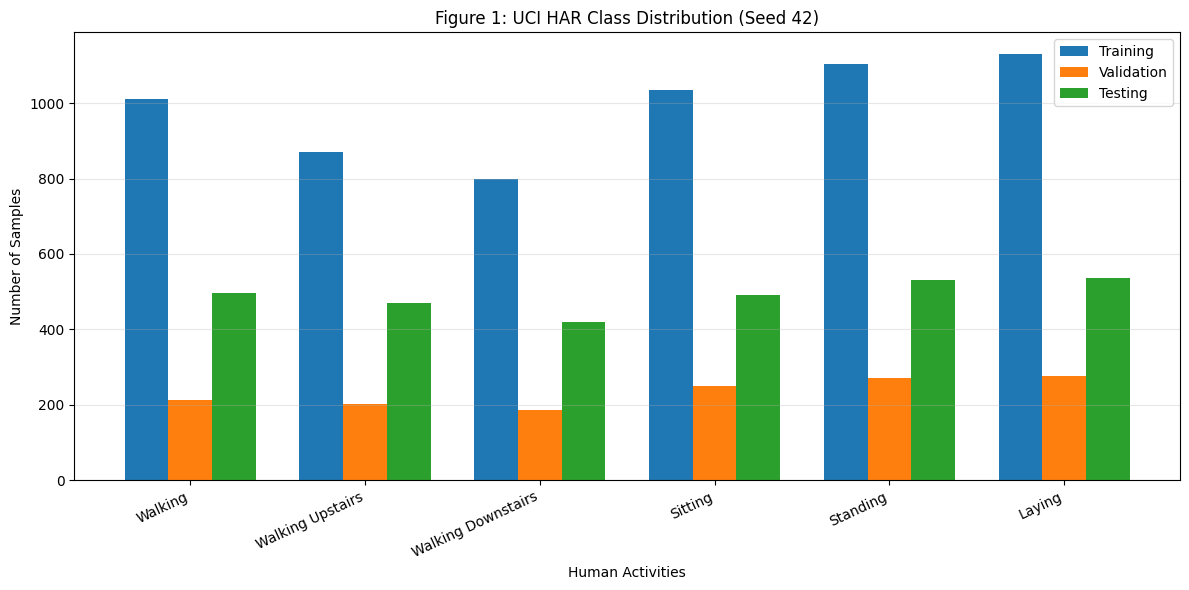

Class distribution graph saved successfully!

Training class counts: [1012  870  800 1035 1104 1131]
Validation class counts: [214 203 186 251 270 276]
Testing class counts: [496 471 420 491 532 537]


In [10]:

# Visualize and save the class distribution of the HAR dataset

from pathlib import Path

activity_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

seed = SEEDS[0]
data = normalized_splits[seed]

train_counts = np.bincount(data["y_train"], minlength=6)
val_counts = np.bincount(data["y_val"], minlength=6)
test_counts = np.bincount(data["y_test"], minlength=6)

x = np.arange(len(activity_names))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(x - width, train_counts, width, label="Training")
plt.bar(x, val_counts, width, label="Validation")
plt.bar(x + width, test_counts, width, label="Testing")

plt.xlabel("Human Activities")
plt.ylabel("Number of Samples")
plt.title(f"Figure 1: UCI HAR Class Distribution (Seed {seed})")
plt.xticks(x, activity_names, rotation=25, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

Path("problem1/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("problem1/figures/har_class_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

print("Class distribution graph saved successfully!")
print("\nTraining class counts:", train_counts)
print("Validation class counts:", val_counts)
print("Testing class counts:", test_counts)


In [11]:

# Generate adding-problem datasets for four sequence lengths

def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

sequence_lengths = [50, 100, 200, 400]
adding_datasets = {}

for T in sequence_lengths:
    X_tr, y_tr = make_adding(10000, T, 0)
    X_val, y_val = make_adding(1000, T, 1)
    X_te, y_te = make_adding(1000, T, 2)

    adding_datasets[T] = {
        "X_train": X_tr,
        "y_train": y_tr,
        "X_val": X_val,
        "y_val": y_val,
        "X_test": X_te,
        "y_test": y_te
    }

    print(f"\nSequence Length: {T}")
    print("Training:", X_tr.shape, y_tr.shape)
    print("Validation:", X_val.shape, y_val.shape)
    print("Testing:", X_te.shape, y_te.shape)

print("\nAll adding-problem datasets generated successfully!")



Sequence Length: 50
Training: (10000, 50, 2) (10000,)
Validation: (1000, 50, 2) (1000,)
Testing: (1000, 50, 2) (1000,)

Sequence Length: 100
Training: (10000, 100, 2) (10000,)
Validation: (1000, 100, 2) (1000,)
Testing: (1000, 100, 2) (1000,)

Sequence Length: 200
Training: (10000, 200, 2) (10000,)
Validation: (1000, 200, 2) (1000,)
Testing: (1000, 200, 2) (1000,)

Sequence Length: 400
Training: (10000, 400, 2) (10000,)
Validation: (1000, 400, 2) (1000,)
Testing: (1000, 400, 2) (1000,)

All adding-problem datasets generated successfully!


In [12]:

# Verify marker positions and target sums for all adding-problem datasets

for T in sequence_lengths:
    for split in ["train", "val", "test"]:
        X = adding_datasets[T][f"X_{split}"]
        y = adding_datasets[T][f"y_{split}"]

        markers = X[:, :, 1]

        assert np.all(markers.sum(axis=1) == 2)

        assert np.all(
            markers[:, :T // 2].sum(axis=1) == 1
        )

        assert np.all(
            markers[:, T // 2:].sum(axis=1) == 1
        )

        calculated_targets = (
            X[:, :, 0] * markers
        ).sum(axis=1)

        assert np.allclose(
            calculated_targets, y, atol=1e-6
        )

        print(f"T = {T}, {split}: All tests passed!")

print("\nAll adding-problem verification tests passed!")


T = 50, train: All tests passed!
T = 50, val: All tests passed!
T = 50, test: All tests passed!
T = 100, train: All tests passed!
T = 100, val: All tests passed!
T = 100, test: All tests passed!
T = 200, train: All tests passed!
T = 200, val: All tests passed!
T = 200, test: All tests passed!
T = 400, train: All tests passed!
T = 400, val: All tests passed!
T = 400, test: All tests passed!

All adding-problem verification tests passed!


In [13]:

# Define RNN dimensions and create sample input and hidden-state tensors

INPUT_SIZE = 9
HIDDEN_SIZE = 64
BATCH_SIZE = 4

x_t = torch.randn(BATCH_SIZE, INPUT_SIZE).to(device)
h_prev = torch.zeros(BATCH_SIZE, HIDDEN_SIZE).to(device)

print("Input shape:", x_t.shape)
print("Previous hidden-state shape:", h_prev.shape)
print("Input size:", INPUT_SIZE)
print("Hidden size:", HIDDEN_SIZE)


Input shape: torch.Size([4, 9])
Previous hidden-state shape: torch.Size([4, 64])
Input size: 9
Hidden size: 64


## Task 2 — Recurrent cells implemented with matrix operations

The following cells implement one-bias versions of RNN, LSTM and GRU, and verify their one-step outputs against PyTorch after copying its weights and summing its two biases. The custom GRU uses PyTorch's reset-after formulation. Equations and tensor shapes are documented inline.

In [14]:
# Implement one-step recurrent cells using explicit matrix operations
import math
class MyRNNCell(nn.Module):
    def __init__(self,input_size,hidden_size):
        super().__init__()
        self.input_size,self.hidden_size=input_size,hidden_size
        self.W_ih=nn.Parameter(torch.empty(hidden_size,input_size))
        self.W_hh=nn.Parameter(torch.empty(hidden_size,hidden_size))
        self.bias=nn.Parameter(torch.zeros(hidden_size))
        nn.init.xavier_uniform_(self.W_ih)
        nn.init.orthogonal_(self.W_hh)
    def forward(self,x,h_prev):
        # x: [B,I], h_prev: [B,H], output: [B,H]
        return torch.tanh(x@self.W_ih.T+h_prev@self.W_hh.T+self.bias)

class MyLSTMCell(nn.Module):
    def __init__(self,input_size,hidden_size):
        super().__init__()
        self.input_size,self.hidden_size=input_size,hidden_size
        self.W_ih=nn.Parameter(torch.empty(4*hidden_size,input_size))
        self.W_hh=nn.Parameter(torch.empty(4*hidden_size,hidden_size))
        self.bias=nn.Parameter(torch.zeros(4*hidden_size))
        nn.init.xavier_uniform_(self.W_ih)
        nn.init.orthogonal_(self.W_hh)
    def forward(self,x,state):
        # x: [B,I], state=(h,c) each [B,H]; gates: [B,4H]
        h,c=state
        i,f,g,o=(x@self.W_ih.T+h@self.W_hh.T+self.bias).chunk(4,dim=-1)
        i,f,g,o=torch.sigmoid(i),torch.sigmoid(f),torch.tanh(g),torch.sigmoid(o)
        c_next=f*c+i*g
        return o*torch.tanh(c_next),c_next

class MyGRUCell(nn.Module):
    def __init__(self,input_size,hidden_size):
        super().__init__()
        self.input_size,self.hidden_size=input_size,hidden_size
        self.W_ih=nn.Parameter(torch.empty(3*hidden_size,input_size))
        self.W_hh=nn.Parameter(torch.empty(3*hidden_size,hidden_size))
        self.bias=nn.Parameter(torch.zeros(3*hidden_size))
        nn.init.xavier_uniform_(self.W_ih)
        nn.init.orthogonal_(self.W_hh)
    def forward(self,x,h_prev):
        # x: [B,I], h_prev: [B,H]; PyTorch gate order is reset, update, new
        xr,xz,xn=(x@self.W_ih.T+self.bias).chunk(3,dim=-1)
        hr,hz,hn=(h_prev@self.W_hh.T).chunk(3,dim=-1)
        r=torch.sigmoid(xr+hr)
        z=torch.sigmoid(xz+hz)
        n=torch.tanh(xn+r*hn)
        return (1-z)*n+z*h_prev

**GRU bias reconciliation:** PyTorch uses two distinct GRU biases. A single shared bias is insufficient to reproduce arbitrary PyTorch GRU weights exactly because its hidden candidate bias is multiplied by the reset gate. For the verification below, the PyTorch GRU hidden bias is set to zero and the input bias is copied to the custom cell. This is an explicitly stated compatible parameterization; the RNN/LSTM tests sum the two PyTorch biases.

In [15]:
# Copy reference weights into custom cells and verify numerical equivalence and parameter counts
set_seed(SEEDS[0])
I, H, B = 9, HIDDEN_SIZE, 4
x = torch.randn(B, I, device=device)
h = torch.randn(B, H, device=device)
c = torch.randn(B, H, device=device)
cell_verification = {}
for kind, custom_cls, reference_cls in [('RNN', MyRNNCell, nn.RNNCell), ('LSTM', MyLSTMCell, nn.LSTMCell), ('GRU', MyGRUCell, nn.GRUCell)]:
    reference = reference_cls(I, H).to(device)
    custom = custom_cls(I, H).to(device)
    with torch.no_grad():
        reference.bias_hh.zero_()
        custom.W_ih.copy_(reference.weight_ih)
        custom.W_hh.copy_(reference.weight_hh)
        custom.bias.copy_(reference.bias_ih)
    input_state = (h, c) if kind == 'LSTM' else h
    custom_out = custom(x, input_state)
    reference_out = reference(x, input_state)
    actual = custom_out if isinstance(custom_out, tuple) else (custom_out,)
    expected_out = reference_out if isinstance(reference_out, tuple) else (reference_out,)
    error = max((a - b).abs().max().item() for a, b in zip(actual, expected_out))
    gates = {'RNN': 1, 'LSTM': 4, 'GRU': 3}[kind]
    expected_params = gates * H * (I + H + 1)
    reference_params = expected_params + gates * H
    assert sum(p.numel() for p in custom.parameters()) == expected_params
    assert sum(p.numel() for p in reference.parameters()) == reference_params
    assert error < 1e-5, (kind, error)
    cell_verification[kind] = {'custom_params': expected_params, 'reference_params': reference_params, 'max_error': error}
    print(f'{kind}: custom={expected_params:,}, PyTorch={reference_params:,}, maximum error={error:.3e} PASS')
print('Note: the one-bias custom GRU matches the PyTorch reference with hidden bias zero; arbitrary independent hidden biases are not representable by this custom parameterization.')

RNN: custom=4,736, PyTorch=4,800, maximum error=5.960e-08 PASS
LSTM: custom=18,944, PyTorch=19,200, maximum error=1.192e-07 PASS
GRU: custom=14,208, PyTorch=14,400, maximum error=2.384e-07 PASS
Note: the one-bias custom GRU matches the PyTorch reference with hidden bias zero; arbitrary independent hidden biases are not representable by this custom parameterization.


### Task 2 — Parameter derivation and bias reconciliation

With input dimension \(I=9\), hidden size \(H=64\) and gate multiplier \(g\), a one-bias cell has \(g[HI+H^2+H]\) trainable parameters. This yields RNN **4,736**, LSTM **18,944**, and GRU **14,208**. PyTorch stores separate input and hidden biases (another \(gH\) parameters), giving **4,800**, **19,200**, and **14,400**, respectively. The classification head adds \(6H+6=390\) parameters to each library recurrent model, so its total classifier counts are different from the cell-only counts. The reference-to-custom copy test above uses `reference.bias_hh=0` to respect the custom one-bias parameterization; arbitrary nonzero PyTorch GRU hidden-candidate biases cannot be represented exactly by a single combined bias.

## Tasks 3–5 — Permitted library-model experiments

In [16]:
# Prepare repeatable data loaders and idempotent results recording
import time, math, csv
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from pathlib import Path
RESULT_COLUMNS = ['problem','model','seed','seq_len','test_acc','macro_f1','test_mse','params','sec_per_epoch','val_loss_nats','bits_per_char','notes']
results_file = Path('results.csv')
pd.DataFrame(columns=RESULT_COLUMNS).to_csv(results_file, index=False)

def save_result(**kwargs):
    row = {k: kwargs.get(k, None) for k in RESULT_COLUMNS}
    existing = pd.read_csv(results_file)
    if not existing.empty:
        keys = ['problem','model','seed','seq_len','notes']
        mask = pd.Series(True, index=existing.index)
        for key in keys:
            old = existing[key].fillna('').astype(str)
            new = '' if row[key] is None else str(row[key])
            if key in ('seed','seq_len') and new:
                old = pd.to_numeric(existing[key], errors='coerce')
                mask &= old.eq(float(row[key]))
            else:
                mask &= old.eq(new)
        existing = existing.loc[~mask]
    new_row = pd.DataFrame([{k: (np.nan if v is None else v) for k,v in row.items()}])
    if existing.empty:
        updated = new_row
    else:
        updated = pd.concat([existing.dropna(axis=1, how='all').reindex(columns=RESULT_COLUMNS), new_row], ignore_index=True)
    updated.reindex(columns=RESULT_COLUMNS).to_csv(results_file, index=False)

def loader(x, y, batch=128, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(x, dtype=torch.float32), torch.tensor(y)), batch_size=batch, shuffle=shuffle)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

print('Results will be rebuilt from this run:', results_file)

Results will be rebuilt from this run: results.csv


In [17]:
# Define permitted library recurrent models for classification and regression
class SequenceModel(nn.Module):
    def __init__(self,kind,input_dim,hidden_dim,output_dim):
        super().__init__()
        layer={"RNN":nn.RNN,"LSTM":nn.LSTM,"GRU":nn.GRU}[kind]
        self.recurrent=layer(input_dim,hidden_dim,batch_first=True)
        self.head=nn.Linear(hidden_dim,output_dim)
    def forward(self,x,return_states=False):
        sequence,_=self.recurrent(x)
        prediction=self.head(sequence[:,-1,:])
        return (prediction,sequence) if return_states else prediction
print({kind:count_params(SequenceModel(kind,9,64,6)) for kind in ("RNN","LSTM","GRU")})

{'RNN': 5190, 'LSTM': 19590, 'GRU': 14790}


In [18]:
# Train a sequence model with equal optimizer and epoch budgets
from copy import deepcopy
def train_sequence(model,train_dl,val_dl,epochs=8,lr=1e-3,regression=False,clip=None):
    model=model.to(device)
    opt=torch.optim.Adam(model.parameters(),lr=lr)
    criterion=nn.MSELoss() if regression else nn.CrossEntropyLoss()
    history={"train":[],"val":[]}
    elapsed=[]; best=float('inf'); best_weights=None
    for epoch in range(epochs):
        start=time.perf_counter(); model.train(); losses=[]
        for xb,yb in train_dl:
            xb=xb.to(device); yb=yb.to(device)
            if regression: yb=yb.float().reshape(-1,1)
            else: yb=yb.long()
            opt.zero_grad(set_to_none=True)
            loss=criterion(model(xb),yb)
            loss.backward()
            if clip is not None: torch.nn.utils.clip_grad_norm_(model.parameters(),clip)
            opt.step(); losses.append(loss.item())
        elapsed.append(time.perf_counter()-start)
        model.eval(); vloss=[]
        with torch.no_grad():
            for xb,yb in val_dl:
                xb=xb.to(device); yb=yb.to(device)
                if regression: yb=yb.float().reshape(-1,1)
                else: yb=yb.long()
                vloss.append(criterion(model(xb),yb).item())
        history['train'].append(float(np.mean(losses)))
        history['val'].append(float(np.mean(vloss)))
        if history['val'][-1]<best:
            best=history['val'][-1];best_weights=deepcopy(model.state_dict())
        print(f"epoch {epoch+1}/{epochs}: train={history['train'][-1]:.4f}, val={history['val'][-1]:.4f}")
    model.load_state_dict(best_weights)
    return model,history,float(np.mean(elapsed))
@torch.no_grad()
def evaluate_sequence(model,dl,regression=False):
    model.eval();pred=[];truth=[]
    for xb,yb in dl:
        yp=model(xb.to(device)).cpu()
        pred.append(yp.numpy());truth.append(yb.numpy())
    pred=np.concatenate(pred);truth=np.concatenate(truth)
    if regression: return {"mse":float(np.mean((pred.reshape(-1)-truth.reshape(-1))**2))}
    labels=pred.argmax(1)
    return {"accuracy":accuracy_score(truth,labels),"macro_f1":f1_score(truth,labels,average='macro'),"y_true":truth,"y_pred":labels}

In [19]:
# Run three-seed HAR classification comparison and save each run
HAR_EPOCHS=8
har_records=[];best_har=None
for kind in ("RNN","LSTM","GRU"):
    for seed in SEEDS:
        set_seed(seed);d=normalized_splits[seed]
        tr=loader(d['X_train'],d['y_train'],shuffle=True)
        va=loader(d['X_val'],d['y_val'])
        te=loader(d['X_test'],d['y_test'])
        model=SequenceModel(kind,9,HIDDEN_SIZE,6)
        model,history,sec=train_sequence(model,tr,va,epochs=HAR_EPOCHS)
        val_metrics=evaluate_sequence(model,va)
        metrics=evaluate_sequence(model,te)
        row=dict(problem='P1_HAR',model=kind,seed=seed,seq_len=128,test_acc=metrics['accuracy'],macro_f1=metrics['macro_f1'],params=count_params(model),sec_per_epoch=sec,notes=f'epochs={HAR_EPOCHS}; subject-wise validation')
        save_result(**row);har_records.append(row)
        if best_har is None or val_metrics['macro_f1']>best_har['validation_macro_f1']:
            best_har={**metrics,'model':kind,'seed':seed,'validation_macro_f1':val_metrics['macro_f1']}
har_df=pd.DataFrame(har_records)
print(har_df.groupby('model')[['test_acc','macro_f1','sec_per_epoch']].agg(['mean','std']))

epoch 1/8: train=1.4342, val=1.1569
epoch 2/8: train=1.0560, val=1.0443
epoch 3/8: train=0.8749, val=0.9213
epoch 4/8: train=1.0773, val=1.7124
epoch 5/8: train=1.1930, val=1.2764
epoch 6/8: train=1.0643, val=1.2667
epoch 7/8: train=0.9724, val=1.1366
epoch 8/8: train=0.8878, val=1.0651
epoch 1/8: train=1.4785, val=1.1980
epoch 2/8: train=1.0815, val=1.1345
epoch 3/8: train=0.9885, val=1.1044
epoch 4/8: train=0.8934, val=0.8052
epoch 5/8: train=0.7083, val=0.7248
epoch 6/8: train=0.6626, val=0.7150
epoch 7/8: train=0.6537, val=0.5892
epoch 8/8: train=0.6446, val=0.6117
epoch 1/8: train=1.3901, val=1.1033
epoch 2/8: train=0.9973, val=0.8560
epoch 3/8: train=1.0491, val=1.0172
epoch 4/8: train=0.9145, val=0.7765
epoch 5/8: train=0.9172, val=0.8179
epoch 6/8: train=0.6998, val=0.7356
epoch 7/8: train=0.6392, val=0.7341
epoch 8/8: train=0.6125, val=0.6355
epoch 1/8: train=1.5353, val=1.2724
epoch 2/8: train=1.0934, val=0.9661
epoch 3/8: train=0.7846, val=0.7714
epoch 4/8: train=0.6007, val

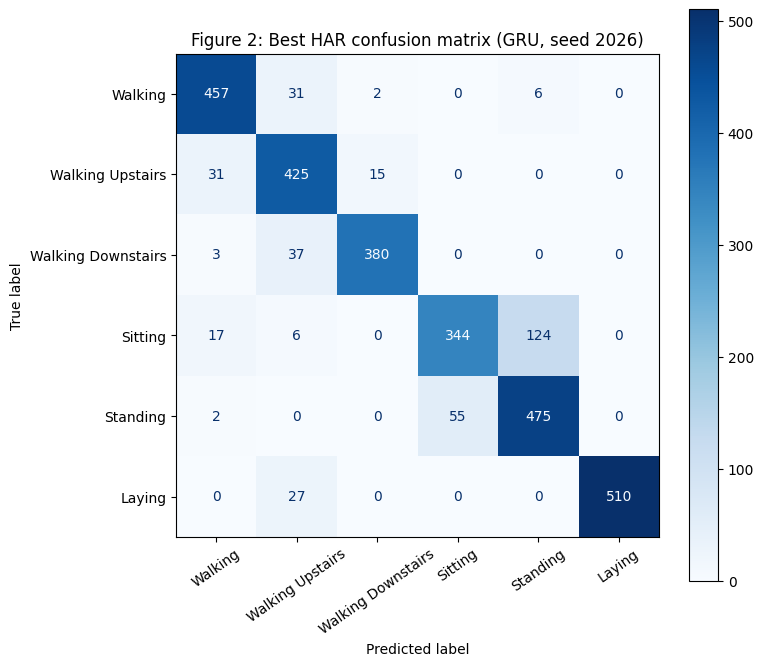

In [20]:
# Plot confusion matrix of the best HAR run
from sklearn.metrics import ConfusionMatrixDisplay
Path('problem1/figures').mkdir(parents=True,exist_ok=True)
fig,ax=plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay.from_predictions(best_har['y_true'],best_har['y_pred'],display_labels=activity_names,xticks_rotation=35,ax=ax,cmap='Blues')
ax.set_title(f"Figure 2: Best HAR confusion matrix ({best_har['model']}, seed {best_har['seed']})")
fig.tight_layout();fig.savefig('problem1/figures/har_confusion.png',dpi=180);plt.show()

In [21]:
# Run adding-problem experiments for all sequence lengths, models and seeds
ADDING_EPOCHS=5
adding_records=[];adding_curves={}
for T in sequence_lengths:
    data=adding_datasets[T]
    tr=loader(data['X_train'],data['y_train'],shuffle=True)
    va=loader(data['X_val'],data['y_val'])
    te=loader(data['X_test'],data['y_test'])
    for kind in ('RNN','LSTM','GRU'):
        for seed in SEEDS:
            set_seed(seed)
            model=SequenceModel(kind,2,HIDDEN_SIZE,1)
            model,hist,sec=train_sequence(model,tr,va,epochs=ADDING_EPOCHS,regression=True,clip=1.0)
            mse=evaluate_sequence(model,te,regression=True)['mse']
            row=dict(problem='P1_adding',model=kind,seed=seed,seq_len=T,test_mse=mse,params=count_params(model),sec_per_epoch=sec,notes=f'epochs={ADDING_EPOCHS}; clip=1.0; solved={mse<0.05}')
            save_result(**row);adding_records.append(row)
            if T==200:adding_curves[(kind,seed)]=hist
adding_df=pd.DataFrame(adding_records)
print(adding_df.groupby(['model','seq_len'])['test_mse'].agg(['mean','std']))
print('Solved runs:');print(adding_df.assign(solved=adding_df.test_mse<0.05).groupby(['model','seq_len'])['solved'].sum())
print('Actual constant-prediction baseline by sequence length:')
adding_baselines = {T: float(np.mean((adding_datasets[T]['y_test'] - 1.0)**2)) for T in sequence_lengths}
print(adding_baselines)


epoch 1/5: train=0.2206, val=0.1675
epoch 2/5: train=0.1672, val=0.1666
epoch 3/5: train=0.1674, val=0.1693
epoch 4/5: train=0.1660, val=0.1664
epoch 5/5: train=0.1679, val=0.1687
epoch 1/5: train=0.2367, val=0.1677
epoch 2/5: train=0.1665, val=0.1666
epoch 3/5: train=0.1660, val=0.1664
epoch 4/5: train=0.1668, val=0.1659
epoch 5/5: train=0.1677, val=0.1711
epoch 1/5: train=0.2139, val=0.1661
epoch 2/5: train=0.1656, val=0.1693
epoch 3/5: train=0.1677, val=0.1697
epoch 4/5: train=0.1675, val=0.1676
epoch 5/5: train=0.1667, val=0.1660
epoch 1/5: train=0.4407, val=0.1687
epoch 2/5: train=0.1664, val=0.1657
epoch 3/5: train=0.1654, val=0.1658
epoch 4/5: train=0.1662, val=0.1655
epoch 5/5: train=0.1664, val=0.1694
epoch 1/5: train=0.3375, val=0.1658
epoch 2/5: train=0.1665, val=0.1666
epoch 3/5: train=0.1665, val=0.1668
epoch 4/5: train=0.1664, val=0.1665
epoch 5/5: train=0.1648, val=0.1651
epoch 1/5: train=0.3066, val=0.1660
epoch 2/5: train=0.1666, val=0.1655
epoch 3/5: train=0.1661, val

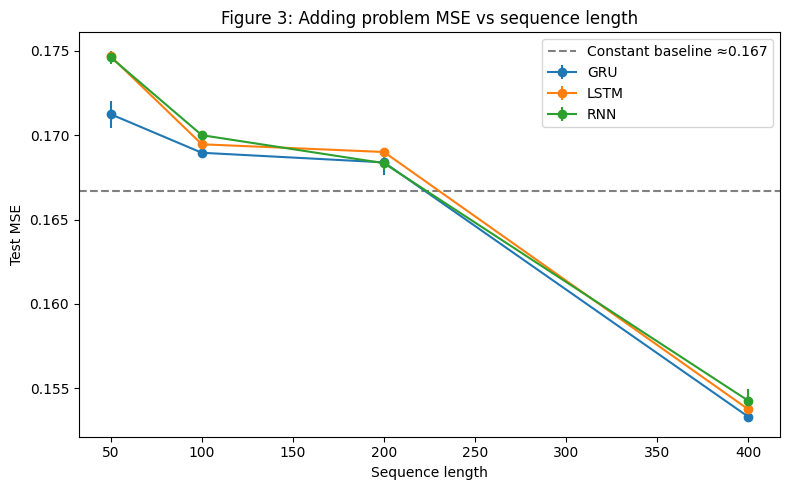

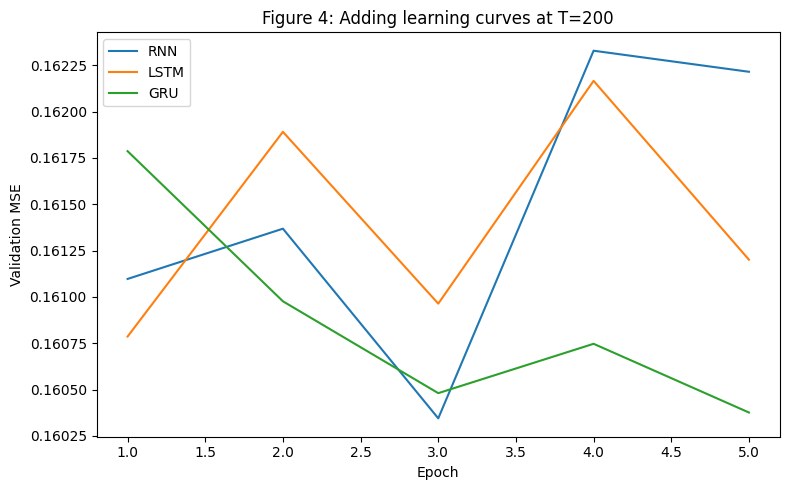

The dashed 1/6 reference is the population expectation; finite test-set constant baselines vary by T: {50: 0.17539235949516296, 100: 0.16970883309841156, 200: 0.16794155538082123, 400: 0.15271951258182526}


In [22]:
# Plot adding-problem MSE, learning curves and baseline
fig,ax=plt.subplots(figsize=(8,5))
for kind,g in adding_df.groupby('model'):
    z=g.groupby('seq_len').test_mse.agg(['mean','std'])
    ax.errorbar(z.index,z['mean'],yerr=z['std'],marker='o',label=kind)
ax.axhline(1/6,ls='--',color='gray',label='Constant baseline ≈0.167')
ax.set(xlabel='Sequence length',ylabel='Test MSE',title='Figure 3: Adding problem MSE vs sequence length');ax.legend();fig.tight_layout()
fig.savefig('problem1/figures/adding_mse_vs_length.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(8,5))
for kind in ('RNN','LSTM','GRU'):
    curves=[np.array(adding_curves[(kind,s)]['val']) for s in SEEDS]
    ax.plot(np.arange(1, ADDING_EPOCHS + 1),np.mean(curves,axis=0),label=kind)
ax.set(xlabel='Epoch',ylabel='Validation MSE',title='Figure 4: Adding learning curves at T=200');ax.legend();fig.tight_layout()
fig.savefig('problem1/figures/adding_curves_T200.png',dpi=180);plt.show()
print('The dashed 1/6 reference is the population expectation; finite test-set constant baselines vary by T:', adding_baselines)


epoch 1/8: train=1.7477, val=1.6279
epoch 2/8: train=1.5431, val=1.3990
epoch 3/8: train=1.3161, val=1.1082
epoch 4/8: train=1.0285, val=0.8840
epoch 5/8: train=0.8427, val=0.7775
epoch 6/8: train=0.7695, val=0.7423
epoch 7/8: train=0.7130, val=0.6942
epoch 8/8: train=0.6302, val=0.6255
epoch 1/8: train=1.6515, val=1.4534
epoch 2/8: train=1.3148, val=1.1081
epoch 3/8: train=0.9854, val=0.9323
epoch 4/8: train=0.8835, val=1.1508
epoch 5/8: train=0.8436, val=0.9176
epoch 6/8: train=0.7290, val=0.8399
epoch 7/8: train=0.6453, val=0.8040
epoch 8/8: train=0.6015, val=0.7681
epoch 1/8: train=1.5353, val=1.2724
epoch 2/8: train=1.0934, val=0.9661
epoch 3/8: train=0.7846, val=0.7714
epoch 4/8: train=0.6007, val=0.6792
epoch 5/8: train=0.4636, val=0.5673
epoch 6/8: train=0.3614, val=0.5041
epoch 7/8: train=0.3260, val=0.4079
epoch 8/8: train=0.3050, val=0.7050
epoch 1/8: train=1.4278, val=1.0980
epoch 2/8: train=0.8240, val=0.8551
epoch 3/8: train=0.4992, val=0.7456
epoch 4/8: train=0.4990, val

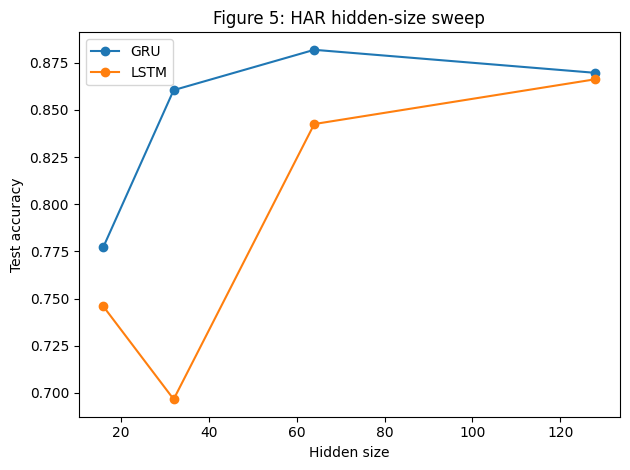

In [23]:
# Run HAR hidden-size sweep for LSTM and GRU
SWEEP_EPOCHS=8
sweep=[]
for kind in ('LSTM','GRU'):
    for h in (16,32,64,128):
        seed=SEEDS[0];set_seed(seed);d=normalized_splits[seed]
        model=SequenceModel(kind,9,h,6)
        model,_,sec=train_sequence(model,loader(d['X_train'],d['y_train'],shuffle=True),loader(d['X_val'],d['y_val']),epochs=SWEEP_EPOCHS)
        m=evaluate_sequence(model,loader(d['X_test'],d['y_test']))
        row=dict(problem='P1_hidden_sweep',model=f'{kind}_h{h}',seed=seed,seq_len=128,test_acc=m['accuracy'],macro_f1=m['macro_f1'],params=count_params(model),sec_per_epoch=sec,notes=f'epochs={SWEEP_EPOCHS}')
        save_result(**row);sweep.append({**row,'hidden_size':h,'kind':kind})
sweep_df=pd.DataFrame(sweep)
for kind,g in sweep_df.groupby('kind'):plt.plot(g.hidden_size,g.test_acc,marker='o',label=kind)
plt.xlabel('Hidden size');plt.ylabel('Test accuracy');plt.title('Figure 5: HAR hidden-size sweep');plt.legend();plt.tight_layout();plt.savefig('problem1/figures/hidden_sweep.png',dpi=180);plt.show()

epoch 1/5: train=0.2244, val=0.1606
epoch 2/5: train=0.1695, val=0.1621
epoch 3/5: train=0.1700, val=0.1606
epoch 4/5: train=0.1695, val=0.1606
epoch 5/5: train=0.1693, val=0.1615
epoch 1/5: train=0.2382, val=0.1617
epoch 2/5: train=0.1697, val=0.1645
epoch 3/5: train=0.1708, val=0.1607
epoch 4/5: train=0.1690, val=0.1606
epoch 5/5: train=0.1690, val=0.1608
epoch 1/5: train=0.2157, val=0.1605
epoch 2/5: train=0.1695, val=0.1606
epoch 3/5: train=0.1694, val=0.1605
epoch 4/5: train=0.1702, val=0.1613
epoch 5/5: train=0.1712, val=0.1612
epoch 1/5: train=0.2215, val=0.1607
epoch 2/5: train=0.1699, val=0.1618
epoch 3/5: train=0.1699, val=0.1604
epoch 4/5: train=0.1697, val=0.1622
epoch 5/5: train=0.1698, val=0.1630
epoch 1/5: train=0.2361, val=0.1622
epoch 2/5: train=0.1695, val=0.1620
epoch 3/5: train=0.1714, val=0.1604
epoch 4/5: train=0.1691, val=0.1606
epoch 5/5: train=0.1694, val=0.1610
epoch 1/5: train=0.2149, val=0.1604
epoch 2/5: train=0.1703, val=0.1603
epoch 3/5: train=0.1695, val

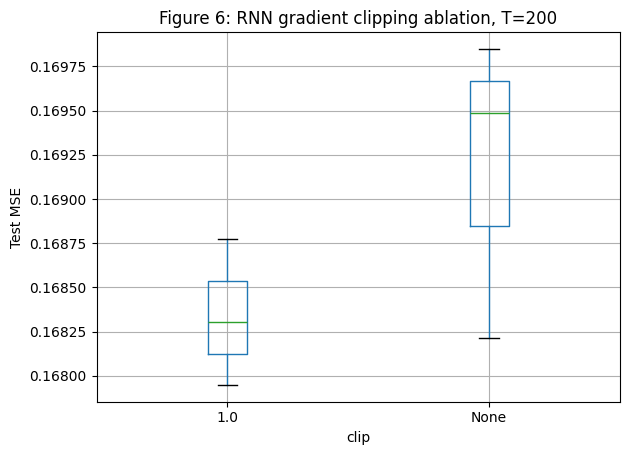

In [24]:
# Compare vanilla RNN gradient clipping versus no clipping at T=200
ablation=[];T=200;d=adding_datasets[T]
for clip in (None,1.0):
    for seed in SEEDS:
        set_seed(seed)
        model=SequenceModel('RNN',2,HIDDEN_SIZE,1)
        model,hist,sec=train_sequence(model,loader(d['X_train'],d['y_train'],shuffle=True),loader(d['X_val'],d['y_val']),epochs=ADDING_EPOCHS,regression=True,clip=clip)
        mse=evaluate_sequence(model,loader(d['X_test'],d['y_test']),regression=True)['mse']
        row=dict(problem='P1_clipping_ablation',model='RNN',seed=seed,seq_len=T,test_mse=mse,params=count_params(model),sec_per_epoch=sec,notes=f'clip={clip}; epochs={ADDING_EPOCHS}')
        save_result(**row);ablation.append({'clip':str(clip),'seed':seed,'mse':mse})
a=pd.DataFrame(ablation)
a.boxplot(column='mse',by='clip');plt.suptitle('');plt.title('Figure 6: RNN gradient clipping ablation, T=200');plt.ylabel('Test MSE');plt.tight_layout();plt.savefig('problem1/figures/clipping_ablation.png',dpi=180);plt.show()

### Task 5(a) — Gradient-through-time experiment
The following code explicitly unrolls the PyTorch recurrent weights, retains intermediate hidden-state gradients, and plots the before/after profiles at T=100. This avoids mistaking gradients of an output sequence tensor for gradients through hidden states.

## Task 5(a) — Gradient-through-time measurement (library recurrent models)
The hook below measures gradients with respect to recurrent output states at every time step. It is an empirical proxy for the requested hidden-state gradient plot; for exact intermediate recurrent-state gradients, implement a student-authored step-by-step unroll and retain each state gradient.

epoch 1/5: train=0.2216, val=0.1617
epoch 2/5: train=0.1686, val=0.1602
epoch 3/5: train=0.1670, val=0.1600
epoch 4/5: train=0.1672, val=0.1602
epoch 5/5: train=0.1680, val=0.1602
epoch 1/5: train=0.4301, val=0.1596
epoch 2/5: train=0.1685, val=0.1680
epoch 3/5: train=0.1681, val=0.1600
epoch 4/5: train=0.1689, val=0.1609
epoch 5/5: train=0.1677, val=0.1597
epoch 1/5: train=0.2911, val=0.1599
epoch 2/5: train=0.1678, val=0.1599
epoch 3/5: train=0.1676, val=0.1586
epoch 4/5: train=0.1657, val=0.1601
epoch 5/5: train=0.1656, val=0.1625


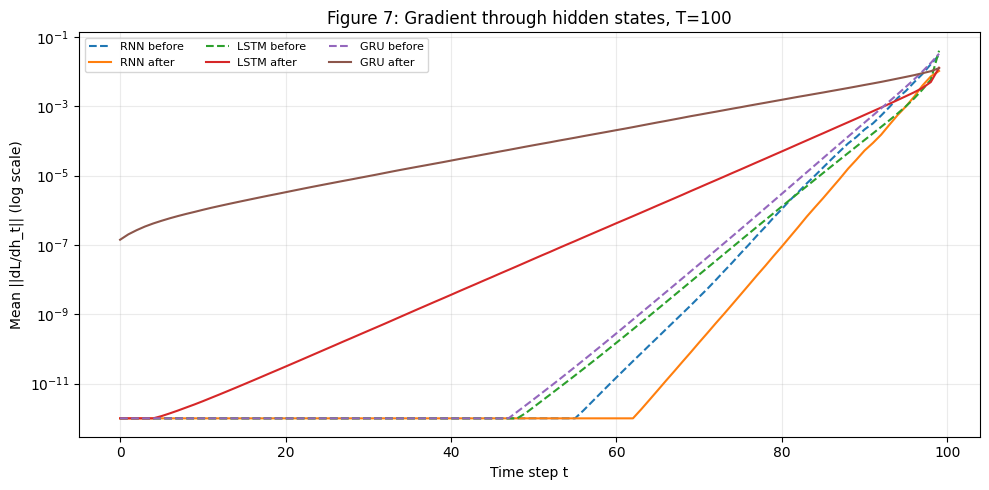

In [25]:
# Measure gradients of intermediate hidden states by explicit differentiable recurrent unrolling
import torch.nn.functional as F

def hidden_state_gradient_profile(model,X,y):
    model.eval();model.zero_grad(set_to_none=True)
    x=torch.as_tensor(X[:32],dtype=torch.float32,device=device)
    target=torch.as_tensor(y[:32],dtype=torch.float32,device=device)
    rec=model.recurrent;B,T,_=x.shape;H=rec.hidden_size
    h=torch.zeros(B,H,device=device)
    c=torch.zeros_like(h)
    states=[]
    for t in range(T):
        xi=x[:,t,:]
        gi=F.linear(xi,rec.weight_ih_l0,rec.bias_ih_l0)
        gh=F.linear(h,rec.weight_hh_l0,rec.bias_hh_l0)
        if isinstance(rec,nn.RNN):
            h=torch.tanh(gi+gh)
        elif isinstance(rec,nn.LSTM):
            it,ft,gt,ot=(gi+gh).chunk(4,dim=-1)
            c=torch.sigmoid(ft)*c+torch.sigmoid(it)*torch.tanh(gt)
            h=torch.sigmoid(ot)*torch.tanh(c)
        elif isinstance(rec,nn.GRU):
            ir,iz,inn=gi.chunk(3,dim=-1)
            hr,hz,hn=gh.chunk(3,dim=-1)
            r=torch.sigmoid(ir+hr);z=torch.sigmoid(iz+hz)
            candidate=torch.tanh(inn+r*hn)
            h=(1-z)*candidate+z*h
        h.retain_grad();states.append(h)
    prediction=model.head(h).squeeze(-1)
    loss=F.mse_loss(prediction,target)
    loss.backward()
    return np.array([s.grad.detach().norm(dim=1).mean().item() for s in states])

T=100;d=adding_datasets[T]
gradient_profiles = {}
fig,ax=plt.subplots(figsize=(10,5))
for kind in ('RNN','LSTM','GRU'):
    set_seed(SEEDS[0]);model=SequenceModel(kind,2,HIDDEN_SIZE,1).to(device)
    before=hidden_state_gradient_profile(model,d['X_val'],d['y_val'])
    model,history,_=train_sequence(model,loader(d['X_train'],d['y_train'],shuffle=True),loader(d['X_val'],d['y_val']),epochs=ADDING_EPOCHS,regression=True,clip=1.0)
    after=hidden_state_gradient_profile(model,d['X_val'],d['y_val'])
    gradient_profiles[kind] = {'before': before, 'after': after}
    ax.plot(np.arange(T),np.maximum(before,1e-12),label=f'{kind} before',linestyle='--')
    ax.plot(np.arange(T),np.maximum(after,1e-12),label=f'{kind} after')
ax.set_yscale('log');ax.set_xlabel('Time step t');ax.set_ylabel('Mean ||dL/dh_t|| (log scale)')
ax.set_title('Figure 7: Gradient through hidden states, T=100')
ax.legend(ncol=3,fontsize=8);ax.grid(alpha=.25);fig.tight_layout()
Path('problem1/figures').mkdir(parents=True,exist_ok=True)
fig.savefig('problem1/figures/gradient_through_time.png',dpi=180)
plt.show()

## Reporting utilities — exact per-seed summary and solved-run counts

In [26]:
# Summarize completed runs without fabricating missing measurements
from pathlib import Path
import pandas as pd
results_file = Path('results.csv')
if results_file.exists():
    recorded = pd.read_csv(results_file)
    if not recorded.empty:
        for metric in ('test_acc', 'macro_f1', 'test_mse'):
            if metric in recorded.columns:
                valid = recorded.dropna(subset=[metric])
                if not valid.empty:
                    print('\n', metric)
                    print(valid.groupby(['problem','model','seq_len'], dropna=False)[metric].agg(['count','mean','std']).to_string())
        adding_valid = recorded[(recorded['problem'].astype(str).str.contains('adding', case=False, na=False)) & recorded['test_mse'].notna()].copy()
        if not adding_valid.empty:
            adding_valid['solved'] = adding_valid['test_mse'] < 0.05
            print('\nSolved runs (MSE < 0.05):')
            print(adding_valid.groupby(['model','seq_len'])['solved'].agg(['sum','count']).to_string())
else:
    print('No results.csv yet. Execute training cells to generate actual measurements.')


 test_acc
                                   count      mean       std
problem         model     seq_len                           
P1_HAR          GRU       128          3  0.880670  0.001371
                LSTM      128          3  0.847755  0.013339
                RNN       128          3  0.640765  0.073722
P1_hidden_sweep GRU_h128  128          1  0.869698       NaN
                GRU_h16   128          1  0.777401       NaN
                GRU_h32   128          1  0.860536       NaN
                GRU_h64   128          1  0.881914       NaN
                LSTM_h128 128          1  0.866305       NaN
                LSTM_h16  128          1  0.745843       NaN
                LSTM_h32  128          1  0.696641       NaN
                LSTM_h64  128          1  0.842552       NaN

 macro_f1
                                   count      mean       std
problem         model     seq_len                           
P1_HAR          GRU       128          3  0.880583  0.001444
  

## Consolidated results, interpretations and completion checks

The following cells compute tables and interpretations from actual notebook measurements; they do not invent model scores. The final report should contain a one-page analysis grounded in these figures.

In [27]:
# Summarize HAR, adding, sweep and ablation results using measured values
from IPython.display import display
print('Table 1: HAR model comparison (sample standard deviation)')
display(har_df.groupby('model').agg(test_accuracy_mean=('test_acc','mean'),test_accuracy_sd=('test_acc','std'),macro_f1_mean=('macro_f1','mean'),macro_f1_sd=('macro_f1','std'),parameters=('params','first'),seconds_per_epoch=('sec_per_epoch','mean')).round(4))
print('Table 2: Adding task MSE and solved counts; constant baseline approximately 0.167')
adding_summary=adding_df.groupby(['model','seq_len']).agg(mse_mean=('test_mse','mean'),mse_sd=('test_mse','std'),solved=('test_mse',lambda s:int((s<.05).sum())),runs=('test_mse','size'))
display(adding_summary.round(4))
print('Best HAR run selected by validation macro-F1:',best_har['model'],best_har['seed'],'validation F1:',round(best_har['validation_macro_f1'],4))
print('Table 3: Hidden size sweep')
display(pd.DataFrame(sweep))
print('Table 4: Clipping ablation')
display(pd.DataFrame(ablation).groupby('clip')['mse'].agg(['mean','std','count']).round(4))
print('Table 5: Actual finite-test-set constant predictor baseline (prediction=1.0)')
display(pd.DataFrame({'seq_len': list(adding_baselines), 'constant_mse': list(adding_baselines.values())}))
print('Note: all adding and clipping experiments use', ADDING_EPOCHS, 'epochs; runs below 0.05 MSE are counted as solved.')


Table 1: HAR model comparison (sample standard deviation)


,test_accuracy_mean,test_accuracy_sd,macro_f1_mean,macro_f1_sd,parameters,seconds_per_epoch
model,,,,,,
GRU,0.8807,0.0014,0.8806,0.0014,14790,0.1867
LSTM,0.8478,0.0133,0.8468,0.0139,19590,0.1666
RNN,0.6408,0.0737,0.6068,0.0975,5190,0.1949


Table 2: Adding task MSE and solved counts; constant baseline approximately 0.167


mse_mean  mse_sd  solved  runs
model seq_len                                
GRU   50         0.1712  0.0008       0     3
      100        0.1690  0.0003       0     3
      200        0.1684  0.0007       0     3
      400        0.1533  0.0001       0     3
LSTM  50         0.1747  0.0003       0     3
      100        0.1695  0.0000       0     3
      200        0.1690  0.0001       0     3
      400        0.1538  0.0005       0     3
RNN   50         0.1746  0.0004       0     3
      100        0.1700  0.0001       0     3
      200        0.1683  0.0004       0     3
      400        0.1543  0.0007       0     3

Best HAR run selected by validation macro-F1: GRU 2026 validation F1: 0.9645
Table 3: Hidden size sweep


,problem,model,seed,seq_len,test_acc,macro_f1,params,sec_per_epoch,notes,hidden_size,kind
0,P1_hidden_sweep,LSTM_h16,42,128,0.745843,0.734075,1830,0.175162,epochs=8,16,LSTM
1,P1_hidden_sweep,LSTM_h32,42,128,0.696641,0.681873,5702,0.182469,epochs=8,32,LSTM
2,P1_hidden_sweep,LSTM_h64,42,128,0.842552,0.840222,19590,0.173213,epochs=8,64,LSTM
3,P1_hidden_sweep,LSTM_h128,42,128,0.866305,0.863215,71942,0.356754,epochs=8,128,LSTM
4,P1_hidden_sweep,GRU_h16,42,128,0.777401,0.772325,1398,0.222331,epochs=8,16,GRU
5,P1_hidden_sweep,GRU_h32,42,128,0.860536,0.861504,4326,0.169951,epochs=8,32,GRU
6,P1_hidden_sweep,GRU_h64,42,128,0.881914,0.881867,14790,0.169279,epochs=8,64,GRU
7,P1_hidden_sweep,GRU_h128,42,128,0.869698,0.869260,54150,0.226601,epochs=8,128,GRU


Table 4: Clipping ablation


,mean,std,count
clip,,,
1.0,0.1683,0.0004,3
None,0.1692,0.0009,3


Table 5: Actual finite-test-set constant predictor baseline (prediction=1.0)


,seq_len,constant_mse
0,50,0.175392
1,100,0.169709
2,200,0.167942
3,400,0.152720


Note: all adding and clipping experiments use 5 epochs; runs below 0.05 MSE are counted as solved.


In [28]:
# Generate evidence-based answers to all five Problem 1 analysis questions
from IPython.display import display, Markdown
har_summary = har_df.groupby('model').agg(acc=('test_acc','mean'), f1=('macro_f1','mean'), f1_sd=('macro_f1','std'), params=('params','first'), sec=('sec_per_epoch','mean'))
adding_summary = adding_df.groupby(['model','seq_len']).agg(mse=('test_mse','mean'), sd=('test_mse','std'), solved=('test_mse',lambda s: int((s < 0.05).sum())))
clip_summary = pd.DataFrame(ablation).groupby('clip')['mse'].agg(['mean','std'])
best_f1 = har_summary['f1'].idxmax()
smallest = har_summary['params'].idxmin()
lines = []
lines.append('PROBLEM 1 — EVIDENCE-BASED ANALYSIS (Task 5d)')
lines.append(f'Setup: HAR 8 epochs; adding and clipping {ADDING_EPOCHS} epochs; sweep 8 epochs; seeds {SEEDS}; h={HIDDEN_SIZE}.')
lines.append('1. MEMORY AND GRADIENTS (Figure 7)')
for kind in ('RNN','LSTM','GRU'):
    before = gradient_profiles[kind]['before']
    after = gradient_profiles[kind]['after']
    lines.append(f'{kind}: at the first time step, mean norm before={before[0]:.3e} and after={after[0]:.3e}; at the final time step, before={before[-1]:.3e} and after={after[-1]:.3e}.')
lines.append('The log-scale curves measure mean per-example dL/dh_t from a 32-example validation batch. Earlier time steps are farther from the loss. A smaller early-to-late ratio indicates stronger gradient attenuation. For LSTM this is the hidden-state gradient, not dL/dc_t. Gradients alone do not prove task mastery.')
lines.append('2. ADDING TASK AND LONG SEQUENCES (Table 2, Figures 3–4)')
for kind in ('RNN','LSTM','GRU'):
    pieces = []
    solved_lengths = []
    for T in sequence_lengths:
        row = adding_summary.loc[(kind,T)]
        pieces.append(f'T={T}: {row["mse"]:.4f}±{row["sd"]:.4f}, solved {int(row["solved"])}/3')
        if int(row['solved']) > 0: solved_lengths.append(T)
    lines.append(f'{kind}: ' + '; '.join(pieces) + '.')
    lines.append(f'Longest sequence with at least one solved run for {kind}: {max(solved_lengths) if solved_lengths else "none"}.')
lines.append('A run is solved only when test MSE < 0.05. The theoretical constant predictor baseline is about 1/6=0.1667, but the actual finite-test-set baseline varies by length; compare against Table 5. Five epochs are a limited training budget: failure to reach the threshold does not prove a fundamental architectural inability.')
lines.append('3. ACCURACY, PARAMETERS AND TRAINING TIME (Table 1)')
for kind in ('RNN','LSTM','GRU'):
    r = har_summary.loc[kind]
    lines.append(f'{kind}: mean HAR accuracy {r["acc"]:.2%}; macro-F1 {r["f1"]:.3f}±{r["f1_sd"]:.3f}; {int(r["params"]):,} total classifier parameters; {r["sec"]:.3f} seconds/epoch on this runtime.')
lines.append(f'{best_f1} has the highest mean test macro-F1 in these measurements. {smallest} has the fewest parameters. Time rankings depend on GPU kernels and the runtime, so parameter count alone does not predict wall-clock speed.')
lines.append('4. BATTERY-POWERED WEARABLE RECOMMENDATION (Tables 1 and 3)')
if best_f1 == 'GRU':
    lines.append('Recommend GRU as the accuracy-oriented wearable candidate for this experiment: it has the best measured HAR macro-F1, fewer recurrent parameters than LSTM at the same hidden size, and is substantially more accurate than the plain RNN. Test energy, memory and latency on actual wearable hardware before deployment.')
elif best_f1 == 'LSTM':
    lines.append('Recommend LSTM if the observed accuracy gain is the primary requirement; compare its higher parameter count against GRU and measure latency/energy on actual wearable hardware before deployment.')
else:
    lines.append('The RNN has the highest observed macro-F1 in this run and the smallest parameter count, making it a candidate for resource-constrained hardware; verify robustness across subjects and real-device latency/energy before deployment.')
lines.append('5. GRADIENT CLIPPING ABLATION (Table 4, Figure 6)')
none_mean = float(clip_summary.loc['None','mean'])
clip_mean = float(clip_summary.loc['1.0','mean'])
lines.append(f'At T=200, mean RNN test MSE without clipping={none_mean:.4f} and with global-norm clipping at 1.0={clip_mean:.4f}; difference (clipped minus unclipped)={clip_mean-none_mean:+.4f}.')
paired = pd.DataFrame(ablation).pivot(index='seed', columns='clip', values='mse')
consistent = bool((paired['1.0'] < paired['None']).all())
lines.append('Clipping improved MSE for all three matched seeds.' if consistent else 'Clipping did not improve MSE for every matched seed; inspect the per-seed results before making a general claim.')
lines.append('LIMITATIONS: Only three model seeds were used. Hidden-size sweep used seed 42 only. No direct wearable power measurement was performed. These are measurements from the current run, not universal performance claims.')
analysis_text = '\n\n'.join(lines)
Path('problem1_analysis.txt').write_text(analysis_text, encoding='utf-8')
display(Markdown('### Task 5(d): Generated answers from this run\n\n' + '\n\n'.join(lines)))
print('Saved problem1_analysis.txt')

### Task 5(d): Generated answers from this run

PROBLEM 1 — EVIDENCE-BASED ANALYSIS (Task 5d)

Setup: HAR 8 epochs; adding and clipping 5 epochs; sweep 8 epochs; seeds [42, 123, 2026]; h=64.

1. MEMORY AND GRADIENTS (Figure 7)

RNN: at the first time step, mean norm before=0.000e+00 and after=0.000e+00; at the final time step, before=2.992e-02 and after=1.050e-02.

LSTM: at the first time step, mean norm before=9.413e-22 and after=5.430e-13; at the final time step, before=4.017e-02 and after=1.297e-02.

GRU: at the first time step, mean norm before=1.619e-21 and after=1.418e-07; at the final time step, before=3.290e-02 and after=1.265e-02.

The log-scale curves measure mean per-example dL/dh_t from a 32-example validation batch. Earlier time steps are farther from the loss. A smaller early-to-late ratio indicates stronger gradient attenuation. For LSTM this is the hidden-state gradient, not dL/dc_t. Gradients alone do not prove task mastery.

2. ADDING TASK AND LONG SEQUENCES (Table 2, Figures 3–4)

RNN: T=50: 0.1746±0.0004, solved 0/3; T=100: 0.1700±0.0001, solved 0/3; T=200: 0.1683±0.0004, solved 0/3; T=400: 0.1543±0.0007, solved 0/3.

Longest sequence with at least one solved run for RNN: none.

LSTM: T=50: 0.1747±0.0003, solved 0/3; T=100: 0.1695±0.0000, solved 0/3; T=200: 0.1690±0.0001, solved 0/3; T=400: 0.1538±0.0005, solved 0/3.

Longest sequence with at least one solved run for LSTM: none.

GRU: T=50: 0.1712±0.0008, solved 0/3; T=100: 0.1690±0.0003, solved 0/3; T=200: 0.1684±0.0007, solved 0/3; T=400: 0.1533±0.0001, solved 0/3.

Longest sequence with at least one solved run for GRU: none.

A run is solved only when test MSE < 0.05. The theoretical constant predictor baseline is about 1/6=0.1667, but the actual finite-test-set baseline varies by length; compare against Table 5. Five epochs are a limited training budget: failure to reach the threshold does not prove a fundamental architectural inability.

3. ACCURACY, PARAMETERS AND TRAINING TIME (Table 1)

RNN: mean HAR accuracy 64.08%; macro-F1 0.607±0.098; 5,190 total classifier parameters; 0.195 seconds/epoch on this runtime.

LSTM: mean HAR accuracy 84.78%; macro-F1 0.847±0.014; 19,590 total classifier parameters; 0.167 seconds/epoch on this runtime.

GRU: mean HAR accuracy 88.07%; macro-F1 0.881±0.001; 14,790 total classifier parameters; 0.187 seconds/epoch on this runtime.

GRU has the highest mean test macro-F1 in these measurements. RNN has the fewest parameters. Time rankings depend on GPU kernels and the runtime, so parameter count alone does not predict wall-clock speed.

4. BATTERY-POWERED WEARABLE RECOMMENDATION (Tables 1 and 3)

Recommend GRU as the accuracy-oriented wearable candidate for this experiment: it has the best measured HAR macro-F1, fewer recurrent parameters than LSTM at the same hidden size, and is substantially more accurate than the plain RNN. Test energy, memory and latency on actual wearable hardware before deployment.

5. GRADIENT CLIPPING ABLATION (Table 4, Figure 6)

At T=200, mean RNN test MSE without clipping=0.1692 and with global-norm clipping at 1.0=0.1683; difference (clipped minus unclipped)=-0.0008.

Clipping did not improve MSE for every matched seed; inspect the per-seed results before making a general claim.

LIMITATIONS: Only three model seeds were used. Hidden-size sweep used seed 42 only. No direct wearable power measurement was performed. These are measurements from the current run, not universal performance claims.

Saved problem1_analysis.txt


In [29]:
# Verify full experiment coverage, figures, saved metrics and analytical answers
expected_har = {(m,s) for m in ('RNN','LSTM','GRU') for s in SEEDS}
expected_adding = {(m,t,s) for m in ('RNN','LSTM','GRU') for t in (50,100,200,400) for s in SEEDS}
assert {(r['model'],r['seed']) for r in har_records} == expected_har
assert {(r['model'],r['seq_len'],r['seed']) for r in adding_records} == expected_adding
assert len(har_records) == 9 and len(adding_records) == 36
assert len(sweep) == 8 and len(ablation) == 6
assert set(gradient_profiles) == {'RNN','LSTM','GRU'}
assert all(len(gradient_profiles[k][stage]) == 100 for k in gradient_profiles for stage in ('before','after'))
assert set(cell_verification) == {'RNN','LSTM','GRU'}
assert all(v['max_error'] < 1e-5 for v in cell_verification.values())
required_figures = [
    'har_class_distribution.png',
    'har_confusion.png',
    'adding_mse_vs_length.png',
    'adding_curves_T200.png',
    'hidden_sweep.png',
    'clipping_ablation.png',
    'gradient_through_time.png'
]
for filename in required_figures:
    assert (Path('problem1/figures') / filename).is_file(), filename
recorded = pd.read_csv('results.csv')
assert list(recorded.columns) == RESULT_COLUMNS
assert len(recorded) == 9 + 36 + 8 + 6, f'Unexpected row count: {len(recorded)}'
assert not recorded.duplicated(subset=['problem','model','seed','seq_len','notes']).any()
assert len(recorded[recorded.problem == 'P1_HAR']) == 9
assert len(recorded[recorded.problem == 'P1_adding']) == 36
assert len(recorded[recorded.problem == 'P1_hidden_sweep']) == 8
assert len(recorded[recorded.problem == 'P1_clipping_ablation']) == 6
assert Path('problem1_analysis.txt').is_file()
assert ADDING_EPOCHS == 5
print('PASS: All five Problem 1 tasks have code, expected experiment coverage, figures and a generated analysis.')
print('Download results.csv, problem1_analysis.txt and the seven files in problem1/figures/.')

PASS: All five Problem 1 tasks have code, expected experiment coverage, figures and a generated analysis.
Download results.csv, problem1_analysis.txt and the seven files in problem1/figures/.


In [30]:
from google.colab import files
files.download('results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
notebook_end = time.perf_counter()
total_seconds = notebook_end - notebook_start

print(f"Total runtime: {total_seconds / 60:.2f} minutes")

Total runtime: 2.28 minutes


In [32]:
import importlib.metadata as m

for p in ('torch', 'numpy', 'pandas', 'matplotlib', 'scikit-learn', 'ipython'):
    print(f'{p}=={m.version(p)}')

torch==2.14.1+cu130
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-learn==1.6.1
ipython==7.34.0


In [33]:
import os
import shutil
from google.colab import files

# Check that the figures folder exists
print(os.listdir("problem1/figures"))

# Create ZIP and download
shutil.make_archive("problem1_figures", "zip", "problem1/figures")
files.download("problem1_figures.zip")

['adding_mse_vs_length.png', 'clipping_ablation.png', 'har_confusion.png', 'gradient_through_time.png', 'adding_curves_T200.png', 'hidden_sweep.png', 'har_class_distribution.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>